# Тестовые пикчи

Исследовательский ноутбук: рисуем картинки и смотрим, как их режет словарь стикеров.

- режим 1, `line`: линия, квадрат, серая градация, наложение, блок 2x2 на стикер
- режим 2, `simple`: блок 4x4, средний цвет против среднего цвета стикера


In [2]:
import sys
from pathlib import Path

import numpy as np
from PIL import Image, ImageDraw

for candidate in (Path.cwd().resolve(), Path.cwd().resolve().parent):
    if (candidate / "kizaru").is_dir():
        sys.path.insert(0, str(candidate))
        break

from kizaru.pic import (
    LINE_CHARS,
    SIMPLE_CHARS,
    SIMPLE_COLORS,
    STICKERS,
    line_indexes,
    render_pic,
    simple_indexes,
)

LINE_COLORS = np.array([item[1] for item in STICKERS], dtype=np.float32)
print("stickers", len(STICKERS))


stickers 114


In [3]:
def solid(color, size=128):
    return Image.new("RGB", (size, size), color)


def color_stripes(size=128):
    image = Image.new("RGB", (size, size))
    draw = ImageDraw.Draw(image)
    colors = [
        (220, 30, 30),
        (240, 180, 30),
        (30, 160, 60),
        (30, 80, 210),
        (12, 12, 12),
        (245, 245, 245),
    ]
    width = size // len(colors)
    for index, color in enumerate(colors):
        draw.rectangle((index * width, 0, (index + 1) * width, size), fill=color)
    return image


def gray_ramp(size=128):
    array = np.zeros((size, size, 3), dtype=np.uint8)
    for x in range(size):
        array[:, x] = int(255 * x / (size - 1))
    return Image.fromarray(array)


def face(size=160):
    image = Image.new("RGB", (size, size), (10, 10, 14))
    draw = ImageDraw.Draw(image)
    draw.ellipse((28, 34, size - 28, size - 18), fill=(236, 214, 196))
    draw.ellipse((58, 70, 82, 96), fill=(18, 18, 22))
    draw.ellipse((size - 82, 70, size - 58, 96), fill=(18, 18, 22))
    draw.arc((62, 100, size - 62, size - 48), 15, 165, fill=(90, 40, 40), width=4)
    return image


def edge_card(size=128):
    image = Image.new("RGB", (size, size), (250, 250, 250))
    draw = ImageDraw.Draw(image)
    draw.rectangle((0, 0, size // 2, size), fill=(8, 8, 8))
    draw.polygon([(20, 20), (size - 20, size // 2), (20, size - 20)], fill=(230, 40, 40))
    return image


def preview(indexes, colors, scale=6):
    rows, cols = indexes.shape
    canvas = np.zeros((rows * scale, cols * scale, 3), dtype=np.uint8)
    for y in range(rows):
        for x in range(cols):
            canvas[y * scale:(y + 1) * scale, x * scale:(x + 1) * scale] = colors[int(indexes[y, x])]
    return Image.fromarray(canvas)


CASES = [
    ("полоски", color_stripes()),
    ("серый градиент", gray_ramp()),
    ("лицо", face()),
    ("ребро", edge_card()),
]
print([name for name, _ in CASES])


['полоски', 'серый градиент', 'лицо', 'ребро']


полоски
Пикча:
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲
🔴🔴🔴🔥☀️☀️☀️🟢🟢🟢💚🔵🔵🔵▪️⬛⬛⬛⬜⬜⬜🔲

Пикча:
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕☁️☁️🌸🔹🔹🔹♥⚫⚫⚫⬜⬜⬜♡
░░░▒⬜⬜⬜⭕

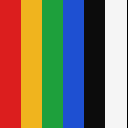

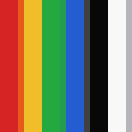

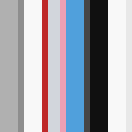

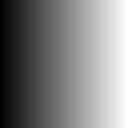

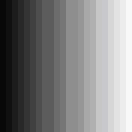

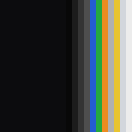

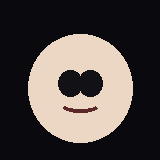

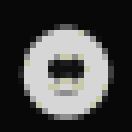

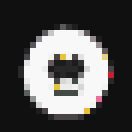

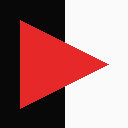

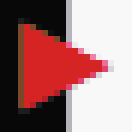

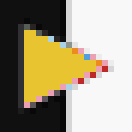

In [4]:
def show_case(name, image, cells=22):
    print(name)
    simple = simple_indexes(np.asarray(image, dtype=np.float32), cells=cells)
    line = line_indexes(np.asarray(image, dtype=np.float32), cells=cells)
    print(render_pic(image, mode="simple", cells=cells))
    print()
    print(render_pic(image, mode="line", cells=cells))
    print()
    return image, preview(simple, SIMPLE_COLORS), preview(line, LINE_COLORS)


PREVIEWS = []
for name, image in CASES:
    source, simple_view, line_view = show_case(name, image)
    PREVIEWS.append((name, source, simple_view, line_view))
